# Modifying SCM input

We've seen what's in the SCM input file and what we can get out of an SCM simulation. Now let's work on modifying the input file for the experiments.

In [55]:
# Setup
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib notebook
%matplotlib inline

The first step is to load the reference `scm_in` input file. I recommend using `xarray.load_dataset` rather than `xarray.open_dataset` because the file sizes are small and you get to see all of the values at once. It also means there is no chance of accidentally overwriting something in the reference input file.

In [56]:
scm_run_name = "ctrl"

In [57]:
# Load the reference input file
ds0 = xr.load_dataset(f'../../scm_runs/{scm_run_name}/scm_in.nc', decode_times=False)

ds0

<xarray.Dataset> Size: 3MB
Dimensions:            (nlev: 137, nlevp1: 138, nlevs: 4, time: 72)
Coordinates:
  * nlev               (nlev) int32 548B 1 2 3 4 5 6 ... 132 133 134 135 136 137
  * nlevp1             (nlevp1) int32 552B 1 2 3 4 5 6 ... 134 135 136 137 138
  * nlevs              (nlevs) int32 16B 1 2 3 4
  * time               (time) int64 576B 0 3600 7200 ... 248400 252000 255600
Data variables: (12/82)
    date               (time) int32 288B 20201008 20201008 ... 20201010 20201010
    second             (time) int32 288B 0 3600 7200 ... 248400 252000 255600
    lat                (time) float64 576B 59.44 59.44 59.44 ... 59.44 59.44
    lon                (time) float64 576B 17.6 17.6 17.6 ... 17.6 17.6 17.6
    pressure_f         (time, nlev) float64 79kB 1.0 2.551 ... 1.007e+05
    pressure_h         (time, nlevp1) float64 79kB 0.0 2.0 ... 1.008e+05
    ...                 ...
    ltlt               (time) float64 576B 284.1 284.1 284.1 ... 283.7 283.7
    lshf               (time) float64 576B 0.6507 0.6507 ... 0.6505 0.6505
    lict               (time) float64 576B 273.1 273.1 273.1 ... 273.1 273.1
    licd               (time) float64 576B 2.289e-05 2.289e-05 ... 2.289e-05
    hour               (time) int64 576B 0 3600 7200 10800 ... 75600 79200 82800
    sfc_ice_albedo     (time) float64 576B 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    title:        SCM input from IFS: valid_t639_2008              
    dataID:      valid_t639_2008               
    coor_par_a:  [0.00000000e+00 2.00036502e+00 3.10224104e+00 4.66608381e+00...
    coor_par_b:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00...

In [58]:
# Define some useful variables for plotting
ZMAX = 3e3  # Maximum height in m
ZEBAR = ds0.height_h.mean('time')
IZ0 = np.nonzero(ZEBAR.data >= ZMAX)[0][-1] - 1
ZEBAR = ZEBAR.isel(nlevp1=slice(IZ0, None))
ZMBAR = ds0.height_f.mean('time').isel(nlev=slice(IZ0, None))
ZLABEL = 'Height, m'

NT = ds0.dims['time']
TMID = np.arange(NT)
TEDGE = np.arange(NT+1) - .5
TLABEL = 'Simulation time, hours'
TTICKS = np.arange(0, NT+1, 12)

/tmp/ipykernel_1069909/4105319119.py:9: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  NT = ds0.dims['time']


## Transition functions

Keeping the forcings smooth is not (usually) necessary but can help with the realism of the simulation. Defining some transition functions can help in making your changes smooth and limiting them to only the areas you want to focus on. Even if you want a perturbation to apply at all times, you will likely _not_ want it to apply to the entire atmospheric column!

Here I will use two simple transition functions:

$$ f_{\text{ramp}}(x) = \begin{cases} x^2 (3 - 2 x) & 0 \leq x \leq 1 \\ 0 & x \leq 0 \\ 1 & 1 \leq x \end{cases} \qquad \qquad f_{\text{bump}}(x) = \begin{cases} (1 - x^2)^2 & -1 \leq x \leq 1 \\ 0 & 1 \leq |x| \end{cases} $$

The ramp function increases from 0 at $x=0$ to 1 at $x=1$, with a derivative of zero at both of these boundaries. It can be used to help introduce (or remove) a change over a time/height range up to a boundary. The bump function increases from 0 at $x=-1$ to 1 at $x=0$ and back to 0 at $x=1$, again with a derivative of zero at both boundaries. It can be used for a perturbation isolated in time/height.

In [59]:
# Define the transition functions
def transition_ramp(x):
    # Restrict the domain from 0 to 1
    x = np.maximum(np.minimum(x, 1), 0)
    return x**2*(3 - 2*x)

def transition_bump(x):
    # Restrict the domain from -1 to 1
    x = np.maximum(np.minimum(x, 1), -1)
    return (1 - x**2)**2

## Varying external forcing

The most direct kind of perturbation would be to one of the external forcing fields, like the geostrophic wind.

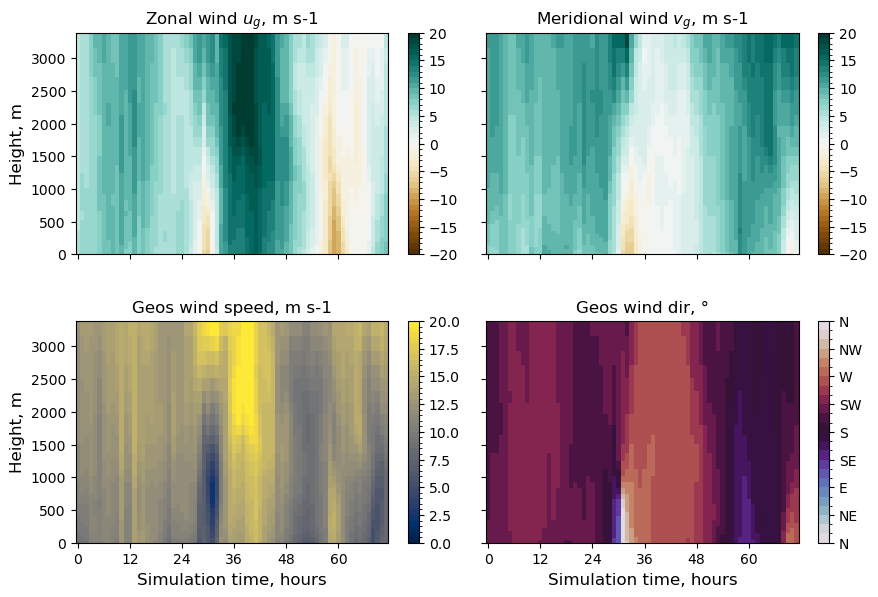

In [60]:
# Plot geostrophic wind in lower atmosphere

# Set up variables to plot
ug = ds0.ug.isel(nlev=slice(IZ0, None))
vg = ds0.vg.isel(nlev=slice(IZ0, None))
wspd = (ug**2 + vg**2)**.5
wdir = np.mod(270 - np.rad2deg(np.arctan2(vg, ug)), 360)
vbls = [
    ('Zonal wind $u_g$, m s-1', ug, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Meridional wind $v_g$, m s-1', vg, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Geos wind speed, m s-1', wspd, mpl.cm.cividis, np.arange(0, 20.1, .5)),
    ('Geos wind dir, \u00B0', wdir, mpl.cm.twilight, np.arange(0, 360.1, 15))
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//2

# Set up figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)

# Plot each variable
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for iplt in range(nplt):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    title, vbl, cmap, cbnds = vbls[iplt]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)

# Customize the last colorbar
cb = cbs[1, 1]
cb.set_ticks(np.arange(0, 360.1, 45))
cb.set_ticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', 'N'])
plt.show()

The first part of the simulation has fairly weak, southwesterly geostrophic wind before transitioning to a much stronger westerly wind. Let's try to make the wind in this first part of the simulation stronger and more southerly. We'll do this by specifying the geostrophic wind below 1 km, transitioning to its original state above 2.5 km, from the start of the simulation. After 12 hours, we'll also transition back to the original velocity over the next 24 hours. We can do this using two ramp functions:

- One ramp in height, going from 0 at 2.5 km to 1 at and below 1 km.
- One ramp in time, going from 1 up to 12 hours to 0 at 36 hours.

In [61]:
# Calculate the transition functions
t0 = 12  # Start the transition at 12 hours
t1 = 36  # End the transition at 36 hours
ttrans = transition_ramp((t1-TMID)/(t1-t0))

z0 = 1e3  # Start the transition at 1.0 km
z1 = 2.5e3  # End the transition at 2.5 km
zmid = ds0.height_f.isel(time=0).data  # Use the initial height as the basis
ztrans = transition_ramp((z1-zmid)/(z1-z0))

# Combine the two 1D functions into one 2D function
trans_total = ttrans[:, np.newaxis] * ztrans[np.newaxis, :]

# print(trans_total.shape,trans_total[0:-1,:].shape)

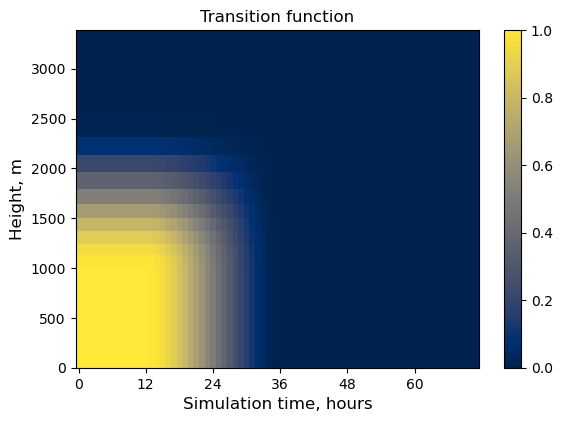

In [62]:
# Plot the transition function
fig, ax = plt.subplots(figsize=(6, 4.5))
fig.subplots_adjust(left=.15, bottom=.15, right=.99, top=.9)
ax.set_xlabel(TLABEL, fontsize=12)
ax.set_xticks(TTICKS)
ax.set_ylabel(ZLABEL, fontsize=12)
ax.set_title('Transition function', fontsize=12)
im = ax.pcolormesh(TEDGE, ZEBAR, trans_total[:, IZ0:].T, cmap=mpl.cm.cividis)
cb = fig.colorbar(im, ax=ax)
plt.show()

The result helps us to isolate most of the changes to the lower 1 km and first 12 hours. Now we combine this with the original speed and direction.

In [63]:
# Use the transition functions to change the wind speed and direction

# Calculate default speed and direction
ug0 = ds0.ug.data
vg0 = ds0.vg.data
wspd0 = (ug0**2 + vg0**2)**.5
wdir0 = np.mod(270 - np.rad2deg(np.arctan2(vg0, ug0)), 360)

# Define new speed and direction
wspd_target = 20.  # 20 m/s
wdir_target = 180.  # Southerly

# Stitch the new and old wind speeds together
wspd_new = wspd0 + (wspd_target-wspd0)*trans_total
wdir_new = wdir0 + (wdir_target-wdir0)*trans_total

# Calculate the component winds
angle = np.deg2rad(270 - wdir_new)
ug_new = wspd_new*np.cos(angle)
vg_new = wspd_new*np.sin(angle)

# Add these winds to a new dataset and save
ds_geosouth = ds0.copy(deep=True)
ds_geosouth.ug.data[...] = ug_new
ds_geosouth.vg.data[...] = vg_new
ds_geosouth.to_netcdf('scm_in_geosouth.nc')

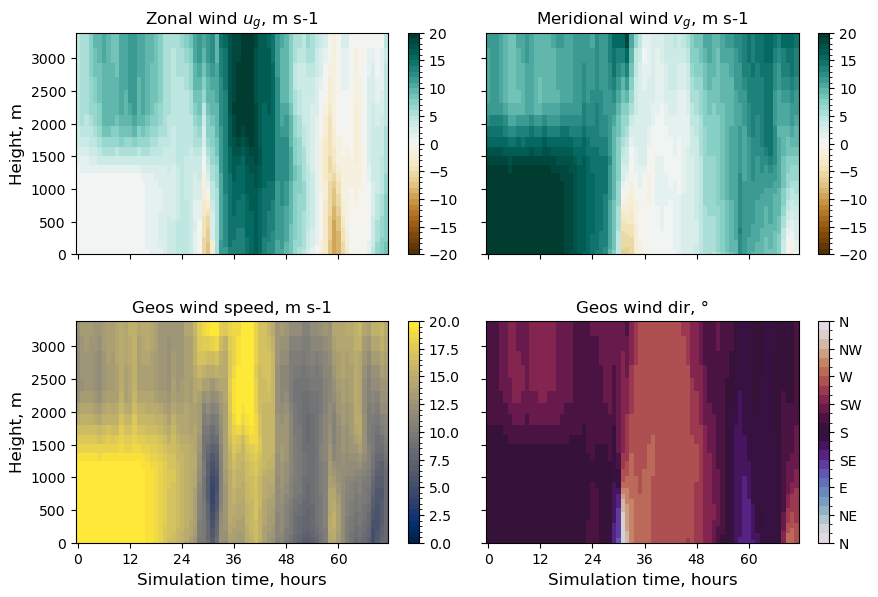

In [64]:
# Plot the new geostrophic wind

# Set up variables to plot
ug = ds_geosouth.ug.isel(nlev=slice(IZ0, None))
vg = ds_geosouth.vg.isel(nlev=slice(IZ0, None))
wspd = (ug**2 + vg**2)**.5
wdir = np.mod(270 - np.rad2deg(np.arctan2(vg, ug)), 360)
vbls = [
    ('Zonal wind $u_g$, m s-1', ug, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Meridional wind $v_g$, m s-1', vg, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Geos wind speed, m s-1', wspd, mpl.cm.cividis, np.arange(0, 20.1, .5)),
    ('Geos wind dir, \u00B0', wdir, mpl.cm.twilight, np.arange(0, 360.1, 15))
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//2

# Set up figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)

# Plot each variable
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for iplt in range(nplt):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    title, vbl, cmap, cbnds = vbls[iplt]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)

# Customize the last colorbar
cb = cbs[1, 1]
cb.set_ticks(np.arange(0, 360.1, 45))
cb.set_ticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', 'N'])
plt.show()

These values can also be given additional structure; the transition function merely helps isolate it. For example, we can put some shear in the wind speed:

In [65]:
# Use the transition functions to change the wind speed and direction

# Calculate default speed and direction
ug0 = ds0.ug.data
vg0 = ds0.vg.data
wspd0 = (ug0**2 + vg0**2)**.5
wdir0 = np.mod(270 - np.rad2deg(np.arctan2(vg0, ug0)), 360)

# Define new speed and direction
# Use the height variable to introduce shear
wspd_target = 10 + 10*zmid/1e3  # 10 m/s at surface, 20 m/s at 1 km
wdir_target = 180.  # Southerly

# Stitch the new and old wind speeds together
wspd_new = wspd0 + (wspd_target-wspd0)*trans_total
wdir_new = wdir0 + (wdir_target-wdir0)*trans_total

# Calculate the component winds
angle = np.deg2rad(270 - wdir_new)
ug_new = wspd_new*np.cos(angle)
vg_new = wspd_new*np.sin(angle)

# Add these winds to a new dataset and save
ds_geoshear = ds0.copy(deep=True)
ds_geoshear.ug.data[...] = ug_new
ds_geoshear.vg.data[...] = vg_new
ds_geoshear.to_netcdf('scm_in_geoshear.nc')

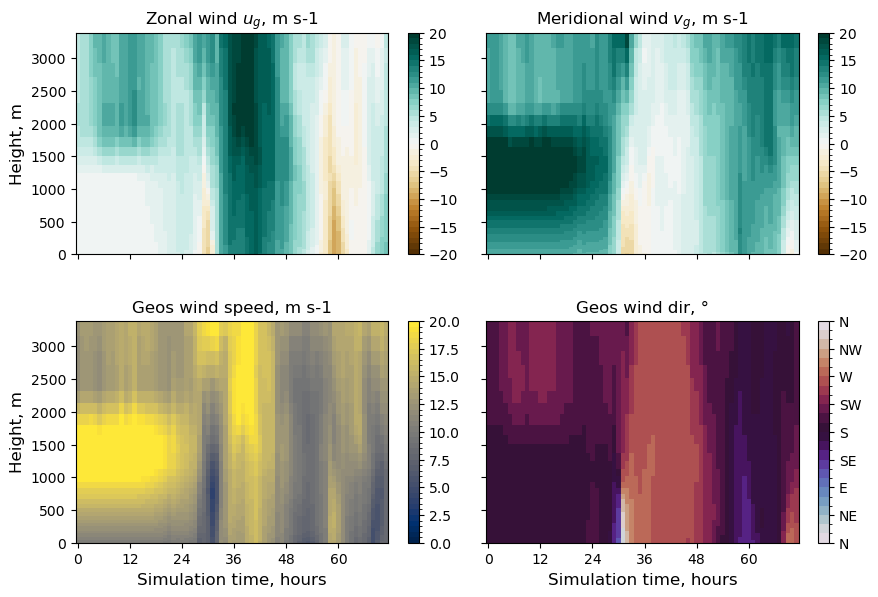

In [66]:
# Plot the new geostrophic wind

# Set up variables to plot
ug = ds_geoshear.ug.isel(nlev=slice(IZ0, None))
vg = ds_geoshear.vg.isel(nlev=slice(IZ0, None))
wspd = (ug**2 + vg**2)**.5
wdir = np.mod(270 - np.rad2deg(np.arctan2(vg, ug)), 360)
vbls = [
    ('Zonal wind $u_g$, m s-1', ug, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Meridional wind $v_g$, m s-1', vg, mpl.cm.BrBG, np.arange(-20, 20.1, 1)),
    ('Geos wind speed, m s-1', wspd, mpl.cm.cividis, np.arange(0, 20.1, .5)),
    ('Geos wind dir, \u00B0', wdir, mpl.cm.twilight, np.arange(0, 360.1, 15))
]
nplt = len(vbls)
ncols = 2
nrows = (nplt+1)//2

# Set up figure
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, sharey=True, figsize=(9, 6))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3, wspace=.05)
for icol in range(ncols):
    axs[-1, icol].set_xlabel(TLABEL, fontsize=12)
    axs[-1, icol].set_xticks(TTICKS)
for irow in range(nrows):
    axs[irow, 0].set_ylabel(ZLABEL, fontsize=12)

# Plot each variable
ims, cbs = [np.empty_like(axs) for __ in range(2)]
for iplt in range(nplt):
    irow, icol = divmod(iplt, ncols)
    ax = axs[irow, icol]
    title, vbl, cmap, cbnds = vbls[iplt]
    ax.set_title(title, fontsize=12)
    norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)
    im = ax.pcolormesh(TEDGE, ZEBAR, vbl.T, cmap=cmap, norm=norm)
    ims[irow, icol] = im
    cbs[irow, icol] = fig.colorbar(im, ax=ax)

# Customize the last colorbar
cb = cbs[1, 1]
cb.set_ticks(np.arange(0, 360.1, 45))
cb.set_ticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', 'N'])
plt.show()

## Varying vertical velocity

For the vertical velocities, however, smoothness is absolutely necessary. Let's look at the vertical advection fields:

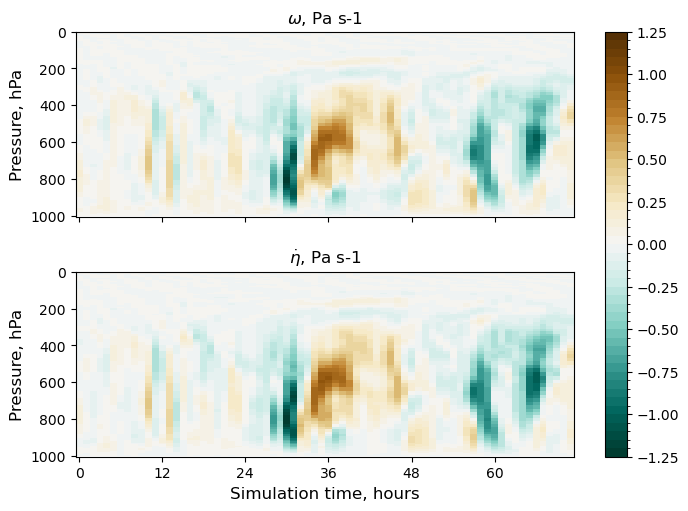

In [67]:
# Plot omega and etadot over the whole atmosphere

# Set up variables to plot
pedge = ds0.pressure_h.isel(time=0).data*1e-2
pedge2 = np.zeros(pedge.size+1)
pedge2[1:-1] = ds0.pressure_f.isel(time=0).data*1e-2
pedge2[[0, -1]] = pedge[[0, -1]]

toplot = [
    dict(title=r'$\omega$, Pa s-1', val=ds0.omega, y=pedge),
    dict(title=r'$\dot{\eta}$, Pa s-1', val=ds0.etadotdpdeta, y=pedge2)
]
nrows = len(toplot)
cmap = mpl.cm.BrBG_r
cbnds = np.arange(-1.25, 1.251, .05)
norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, sharey=True, figsize=(7, 5))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3)
for irow in range(nrows):
    axs[irow].set_ylabel('Pressure, hPa', fontsize=12)
    axs[irow].set_ylim(1005, 0)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)

# Plot each quantity
ims = np.empty_like(axs)
for irow in range(nrows):
    ax = axs[irow]
    pdict = toplot[irow]
    ax.set_title(pdict['title'], fontsize=12)
    ims[irow] = ax.pcolormesh(TEDGE, pdict['y'], pdict['val'].data.T, cmap=cmap, norm=norm)

# Add a common colorbar
cb = fig.colorbar(ims[0], ax=axs.tolist())
cb.set_ticks(np.arange(-1.25, 1.251, .25))
plt.show()

The color scale here is flipped: blue, negative values correspond to lifting and adiabatic cooling whereas brown, positive values correspond to subsidence and adiabatic heating.

These two vertical velocity fields are very closely related to each other but are on slightly different grids. (In fact, if the surface pressure is constant in time (like in the SCM) and there are no gradients of surface pressure, $\omega = \dot{\eta}$.) The primary constraint to keep in mind is that $\dot{\eta} = 0$ at the top and bottom of the atmosphere.

Suppose we want to add some low-level subsidence to the first part of the simulation. We'll use the same transition function approach but with the bump function in height, to make sure the values are 0 again at the surface.

In [68]:
# Define the transition function

# Choose a center point and width in time
t0 = 24  # Primarily over the first 24 hours
t1 = 36  # Over by hour 36
# ttrans = transition_ramp((t1-TMID)/(t1-t0))
ttrans = transition_bump((t1-TMID)/(t1-t0))

# Choose a center point and width in pressure
p0 = 800  # Centered at 800 hPa, about 1.7 km
dp = 150  # Width of 150 hPa on each side
dz = 150  # Width of 150 hPa on each side
z0 = 1
ztrans = transition_bump((pedge-p0)/dp)
# ztrans = transition_bump((z0-zmid)/dz)

# Calculate the combined transition function
trans_total = ttrans[:, np.newaxis] * ztrans[np.newaxis, :]

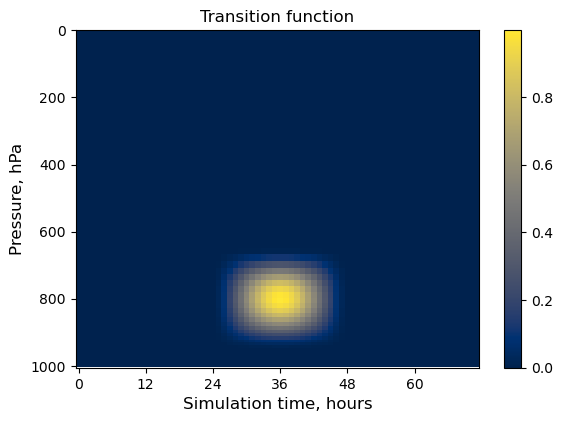

In [69]:
# Plot the transition function
fig, ax = plt.subplots(figsize=(6, 4.5))
fig.subplots_adjust(left=.15, bottom=.15, right=.99, top=.9)
ax.set_xlabel(TLABEL, fontsize=12)
ax.set_xticks(TTICKS)
ax.set_ylabel('Pressure, hPa', fontsize=12)
ax.set_ylim(1005, 0)
ax.set_title('Transition function', fontsize=12)
im = ax.pcolormesh(TEDGE, pedge2, trans_total.T, cmap=mpl.cm.cividis)
cb = fig.colorbar(im, ax=ax)
plt.show()

In [70]:
# Use the transition function to calculate new vertical velocities based on etadot

# Calculate new etadot
etadot0 = ds0.etadotdpdeta.data
etadot_target = .6
etadot_new = etadot0 + (etadot_target-etadot0)*trans_total
# Make sure values at top and bottom are zero
etadot_new[:, [0, -1]] = 0

# Calculate omega as the simple mean of etadot
omega_new = .5*(etadot_new[:, :-1] + etadot_new[:, 1:])

# Create and save a new dataset with these values
ds_subsidence = ds0.copy(deep=True)
ds_subsidence.omega.data[...] = omega_new
ds_subsidence.etadotdpdeta.data[...] = etadot_new
ds_subsidence.to_netcdf('scm_in_subsidence.nc')

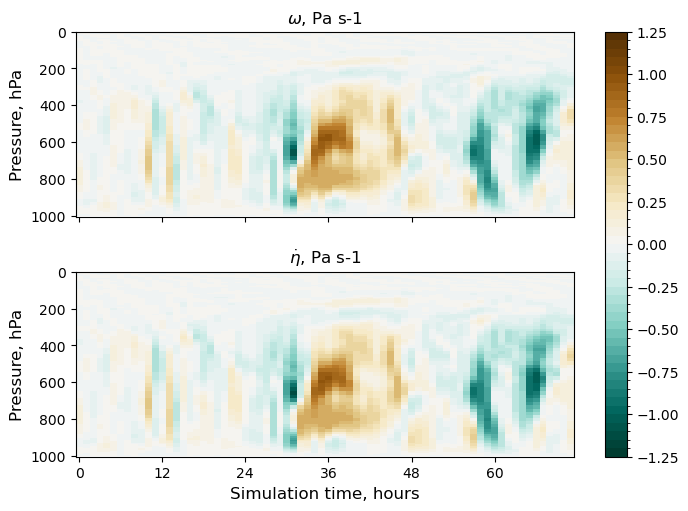

In [71]:
# Plot omega and etadot in the new dataset

# Set up variables to plot
pedge = ds_subsidence.pressure_h.isel(time=0).data*1e-2
pedge2 = np.zeros(pedge.size+1)
pedge2[1:-1] = ds_subsidence.pressure_f.isel(time=0).data*1e-2
pedge2[[0, -1]] = pedge[[0, -1]]

toplot = [
    dict(title=r'$\omega$, Pa s-1', val=ds_subsidence.omega, y=pedge),
    dict(title=r'$\dot{\eta}$, Pa s-1', val=ds_subsidence.etadotdpdeta, y=pedge2)
]
nrows = len(toplot)
cmap = mpl.cm.BrBG_r
cbnds = np.arange(-1.25, 1.251, .05)
norm = mpl.colors.BoundaryNorm(cbnds, cmap.N)

# Set up figure
fig, axs = plt.subplots(nrows=nrows, sharex=True, sharey=True, figsize=(7, 5))
fig.subplots_adjust(left=.1, bottom=.1, right=.99, top=.95, hspace=.3)
for irow in range(nrows):
    axs[irow].set_ylabel('Pressure, hPa', fontsize=12)
    axs[irow].set_ylim(1005, 0)
axs[-1].set_xlabel(TLABEL, fontsize=12)
axs[-1].set_xticks(TTICKS)

# Plot each quantity
ims = np.empty_like(axs)
for irow in range(nrows):
    ax = axs[irow]
    pdict = toplot[irow]
    ax.set_title(pdict['title'], fontsize=12)
    ims[irow] = ax.pcolormesh(TEDGE, pdict['y'], pdict['val'].data.T, cmap=cmap, norm=norm)

# Add a common colorbar
cb = fig.colorbar(ims[0], ax=axs.tolist())
cb.set_ticks(np.arange(-1.25, 1.251, .25))
plt.show()

This has added an extra patch of low-level subsidence in the first part of the simulation. This subsidence will likely suppress boundary layer growth, with the effect getting larger as the boundary layer gets deeper (closer to the 800 hPa center).

## Varying surface properties

One way to set up a perturbation experiment is to vary the surface properties. Let's look at a collection of values related to the vegetation:

In [72]:
vbls = [
    'lsm', 'cl',
    'high_veg_type', 'low_veg_type', 'soty', 'lail', 'laih', 'albedo',
    'high_veg_cover', 'low_veg_cover']
nsvbl = max(len(vbl) for vbl in vbls)
nsname = max(len(ds0[vbl].attrs['long_name']) for vbl in vbls)

print(f'{"Variable":{nsvbl}s} : {"Name":{nsname}s} : {"Value":8s} : Units')
for vbl in vbls:
    da = ds0[vbl]
    name = da.attrs['long_name']
    units = da.attrs['units']
    val = da.data[0]
    print(f'{vbl:{nsvbl}s} : {name:{nsname}s} : {val:8.6f} : {units}')

Variable       : Name                            : Value    : Units
lsm            : Land-Sea Mask                   : 0.522926 : -
cl             : Lake fraction                   : 0.477074 : 1
high_veg_type  : High Vegetation Type            : 3.000000 : 1
low_veg_type   : Low Vegetation Type             : 1.000000 : 1
soty           : Soil Type                       : 1.000000 : 1-6
lail           : Leaf Area Index Low Vegitation  : 2.978394 : m2/m2
laih           : Leaf Area Index High Vegitation : 4.576050 : m2/m2
albedo         : Background Albedo               : 0.071457 : 1
high_veg_cover : High Vegetation Cover           : 0.468719 : 1
low_veg_cover  : Low Vegetation Cover            : 0.026681 : 1


The land-sea mask/lake fraction show that just over half the column is land with the other half occupied by coastal waters (which are included under "lakes" in IFS). From the IFS documentation (part 4, chapter 8) we can translate the different types. The high vegetation is "Evergreen needleleaf trees"; the low vegetation is "Crops, mixed farming"; and the soil type is "Coarse". The surface is dominated by high vegetation that covers most of the land area; the `high_veg_cover` is nearly equal to the `lsm`. This vegetation has a high leaf-area index (LAI) and leads to a very low albedo.

In terms of surface parameters, what can actually be changed are:

- The lake/coastal water coverage;
- The types of vegetation and soil; and
- The coverage of vegetation.

The albedo, surface roughness lengths, and other properties are all based on the surface specification and **cannot be varied independently**.

So how might we set this up to get a brighter, rougher surface? We can increase the amount of land and decrease the coverage of high vegetation, exposing more bare soil. I will do this here and save the resulting file as `scm_in_moreland.nc`.

In [73]:
# Make a dataset with more land surface
ds_moreland = ds0.copy(deep=True)  # Make a copy of the dataset to edit
ds_moreland.cl.data[...] = 0  # Reduce the amount of coastal water
ds_moreland.lsm.data[...] = 1 - ds_moreland.cl.data  # Make the land-sea mask match
ds_moreland.high_veg_cover[...] = 0  # Reduce the high_veg_cover

# Optional; the additional land can either be low vegetation or bare soil
ds_moreland.low_veg_cover[...] = 0  # Make the additional land low vegetation

# Save the result
#ds_moreland.to_netcdf('scm_in_moreland.nc')

We would copy this file over to the server by running (from your machine)

    scp -P 23715 /path/to/scm_in_moreland.nc [user]@130.237.189.40:/home/[user]/scm/data

Then when running the model on the server, use

    ./runscm_c43

to run the model with this input file, which will save the result to the directory `scm-runs/moreland`. You can now exit the server and, from your machine, import the new data by running

    scp -r -P 23715 [user]@130.237.189.40:/home/[user]/scm/scm-runs/moreland  /path/folder/where/you/want/to/save/the/results/

to copy the results back to your machine and analyse them using the other two notebooks (the `-r`flag in Linux is needed when working with folders, by it copying them, removing them, transferring them...).

Happy writing!

## Test

In [74]:
# Input dataset with roughness scaled by 100x and 0.01x

print('mom_rough  :', ds0.mom_rough.attrs.get('long_name'), ds0.mom_rough.attrs.get('units'),
      ds0.mom_rough.data[0])
print('heat_rough :', ds0.heat_rough.attrs.get('long_name'), ds0.heat_rough.attrs.get('units'),
      ds0.heat_rough.data[0])

# 100x rougher
ds_rough = ds0.copy(deep=True)
ds_rough.mom_rough.data[...] = ds0.mom_rough.data * 100
ds_rough.to_netcdf('scm_in_rough.nc')

# 100x smoother
ds_smooth = ds0.copy(deep=True)
ds_smooth.mom_rough.data[...] = ds0.mom_rough.data / 100
ds_smooth.to_netcdf('scm_in_smooth.nc')

print('saved:', ds_rough.mom_rough.data[0], ds_smooth.mom_rough.data[0])

mom_rough  : Momentum Roughness Length m 9.99999901978299e-05
heat_rough : Heat Roughness Length m 1.000100016593933


PermissionError: [Errno 13] Permission denied: '/home/fredrik/Documents/Master in Atmospheric Sciences Oceanography and Climate Physics Stockholm/Turbulent Boundary Layers in the Atmosphere and Ocean (MO8010)/model_lab/Lab____modelling__export/Jupyter_Notebooks/scm_in_rough.nc'